## Section 1: Setup + Load Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_PATH = '/content/drive/MyDrive/inflation-nowcast-th'
df = pd.read_csv(f'{PROJECT_PATH}/data/master_dataset.csv', parse_dates=['date'])
df = df.set_index('date')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,cpi_index,cpi_yoy,cpi_mom,fx_mid_rate_avg,policy_rate,oil_price
date,,,,,,
2020-01-01,92.90,NaN,NaN,30.434764,1.25,63.65
2020-02-01,92.83,NaN,-0.075350,31.335395,1.25,55.66
2020-03-01,92.03,NaN,-0.861790,32.087550,1.00,32.01
2020-04-01,90.16,NaN,-2.031946,32.637771,0.75,18.38
2020-05-01,90.17,NaN,0.011091,32.041711,0.75,29.38


## Section 2: Time Series Overview

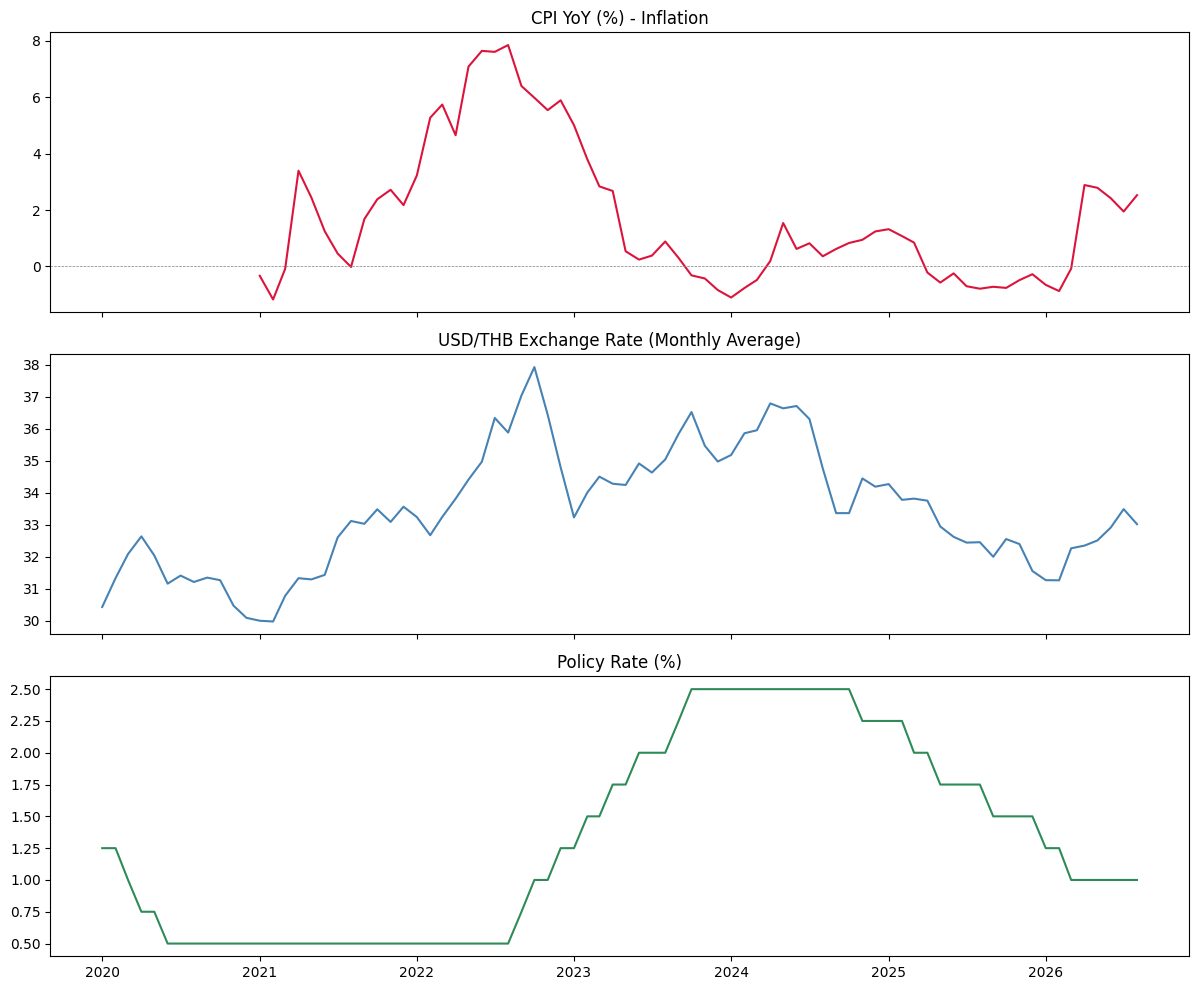

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(df.index, df['cpi_yoy'], color='crimson')
axes[0].set_title('CPI YoY (%) - Inflation')
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.5)

axes[1].plot(df.index, df['fx_mid_rate_avg'], color='steelblue')
axes[1].set_title('USD/THB Exchange Rate (Monthly Average)')

axes[2].plot(df.index, df['policy_rate'], color='seagreen')
axes[2].set_title('Policy Rate (%)')

plt.tight_layout()
plt.show()

## Section 3: Correlation

In [3]:
corr = df[['cpi_yoy', 'fx_mid_rate_avg', 'policy_rate']].corr()
print(corr)

                  cpi_yoy  fx_mid_rate_avg  policy_rate
cpi_yoy          1.000000         0.308615    -0.536346
fx_mid_rate_avg  0.308615         1.000000     0.532216
policy_rate     -0.536346         0.532216     1.000000


Lag Correlation

In [4]:
for lag in [1, 3, 6, 12]:
    corr_lag = df['cpi_yoy'].corr(df['policy_rate'].shift(lag))
    print(f"Policy rate lag {lag} เดือน vs CPI YoY: {corr_lag:.3f}")

Policy rate lag 1 เดือน vs CPI YoY: -0.574
Policy rate lag 3 เดือน vs CPI YoY: -0.615
Policy rate lag 6 เดือน vs CPI YoY: -0.617
Policy rate lag 12 เดือน vs CPI YoY: -0.574


## Section 4: Summary Table of All Correlations

In [5]:
summary = []
for var in ['fx_mid_rate_avg', 'policy_rate']:
    for lag in [0, 1, 3, 6, 12]:
        corr_val = df['cpi_yoy'].corr(df[var].shift(lag))
        summary.append({'variable': var, 'lag_months': lag, 'correlation_with_cpi_yoy': round(corr_val, 3)})

df_corr_summary = pd.DataFrame(summary)
print(df_corr_summary)

df_corr_summary.to_csv(f'{PROJECT_PATH}/data/correlation_summary.csv', index=False)

          variable  lag_months  correlation_with_cpi_yoy
0  fx_mid_rate_avg           0                     0.309
1  fx_mid_rate_avg           1                     0.274
2  fx_mid_rate_avg           3                     0.117
3  fx_mid_rate_avg           6                    -0.047
4  fx_mid_rate_avg          12                    -0.459
5      policy_rate           0                    -0.536
6      policy_rate           1                    -0.574
7      policy_rate           3                    -0.615
8      policy_rate           6                    -0.617
9      policy_rate          12                    -0.574


## Section 6: Feature Engineering

In [6]:
df_feat = df.copy()

df_feat['policy_rate_lag3'] = df_feat['policy_rate'].shift(3)
df_feat['policy_rate_lag6'] = df_feat['policy_rate'].shift(6)

df_feat['fx_lag1'] = df_feat['fx_mid_rate_avg'].shift(1)
df_feat['fx_pct_change_1m'] = df_feat['fx_mid_rate_avg'].pct_change(1) * 100
df_feat['fx_pct_change_3m'] = df_feat['fx_mid_rate_avg'].pct_change(3) * 100

df_feat['cpi_yoy_lag1'] = df_feat['cpi_yoy'].shift(1)

df_feat['oil_lag1'] = df_feat['oil_price'].shift(1)
df_feat['oil_pct_change_1m'] = df_feat['oil_price'].pct_change(1) * 100
df_feat['oil_pct_change_3m'] = df_feat['oil_price'].pct_change(3) * 100

In [7]:
df_feat = df_feat.dropna().reset_index()

print(df_feat.shape)
df_feat.head()

(67, 16)


,date,cpi_index,cpi_yoy,cpi_mom,fx_mid_rate_avg,policy_rate,oil_price,policy_rate_lag3,policy_rate_lag6,fx_lag1,fx_pct_change_1m,fx_pct_change_3m,cpi_yoy_lag1,oil_lag1,oil_pct_change_1m,oil_pct_change_3m
0,2021-02-01,91.74,-1.174189,-0.918026,29.981606,0.5,62.28,0.5,0.5,30.005895,-0.080949,-1.625516,-0.333692,54.77,13.711886,45.888967
1,2021-03-01,91.95,-0.086928,0.228908,30.783583,0.5,65.41,0.5,0.5,29.981606,2.674897,2.282914,-1.174189,62.28,5.025690,30.846169
2,2021-04-01,93.22,3.393966,1.381185,31.333022,0.5,64.81,0.5,0.5,30.783583,1.784846,4.422888,-0.086928,65.41,-0.917291,18.331203
3,2021-05-01,92.37,2.439836,-0.911821,31.295550,0.5,68.53,0.5,0.5,31.333022,-0.119593,4.382502,3.393966,64.81,5.739855,10.035324
4,2021-06-01,92.72,1.244813,0.378911,31.436957,0.5,73.16,0.5,0.5,31.295550,0.451844,2.122477,2.439836,68.53,6.756165,11.848341


In [8]:
df_feat.to_csv(f'{PROJECT_PATH}/data/features_dataset.csv', index=False)